# Задача 4

Используя интегральное представление для функций Бесселя целого индекса $m$

$$
    J_m(x)=\frac{1}{\pi}\int_0^\pi\cos(mt-x\sin t)\,dt
$$

и вычисляя производную с помощью конечной разности в тех же точках, что и сам
интеграл, продемонстрировать выполнение равенства

$$
    J_0'(x)+J_1(x)=0
$$

с точностью не хуже $10^{-10}$ на отрезке $x\in[0,2\pi]$.
Для вычисления интегралов использовать метод трапеций и метод Симпсона.
Продемонстрировать теоретический порядок точности реализованных методов
на последовательности сгущающихся сеток на простых примерах.

---

## Интегральное представление и проверяемое равенство.

При $m=0$ имеем

$$
    J_0(x)=\frac{1}{\pi}\int_0^\pi\cos(x\sin t)\,dt,
    \qquad
    J_0'(x)=-\frac{1}{\pi}\int_0^\pi\sin t\sin(x\sin t)\,dt.
$$

Раскроем косинус разности в интеграле для $J_1$:

$$
    \cos(t-x\sin t)=\cos t\cos(x\sin t)+\sin t\sin(x\sin t).
$$

Интеграл от первого слагаемого равен нулю: при замене $t\mapsto\pi-t$
оно меняет знак. Поэтому

$$
    J_1(x)=\frac{1}{\pi}\int_0^\pi\sin t\sin(x\sin t)\,dt=-J_0'(x).
$$

Это аналитическое объяснение. В программе производную будем получать
**конечной разностью по вычисленным значениям $J_0$**.
Обе функции Бесселя вычислим по исходному интегральному представлению.

## Метод трапеций.

Как в задаче 3, разобьём отрезок $[a,b]$ на $N$ интервалов ширины
$h=(b-a)/N$. Обозначим $t_i=a+ih$ и $c_i=(t_i+t_{i+1})/2$.

$$
    T_N=h\left[\frac{f(t_0)+f(t_N)}{2}
    +\sum_{i=1}^{N-1}f(t_i)\right].
$$

Для $f\in C^2[a,b]$ справедлива оценка

$$
    |I-T_N|\leq\frac{b-a}{12}h^2\max_{[a,b]}|f''(t)|=O(h^2).
$$

In [13]:
import math
import numpy as np
import matplotlib.pyplot as plt


def find_trapezoid(func, a, b, N):
    h = (b - a) / N
    total = (func(a) + func(b)) / 2
    for i in range(1, N):
        total += func(a + i * h)
    return h * total

## Метод Симпсона.

Используем ту же формулу с серединой каждого интервала, что и в задаче 3:

$$
    S_N=\frac{h}{6}\sum_{i=0}^{N-1}
    \left[f(t_i)+4f(c_i)+f(t_{i+1})\right].
$$

Здесь $h$ — ширина целого интервала. Метод использует $2N+1$ узел,
а метод трапеций — $N+1$ узел; $N$ может быть любым положительным целым.
Для $f\in C^4[a,b]$

$$
    |I-S_N|\leq\frac{b-a}{2880}h^4\max_{[a,b]}|f^{(4)}(t)|=O(h^4).
$$

In [14]:
def find_simpson(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(N):
        left = a + i * h
        right = a + (i + 1) * h
        middle = (left + right) / 2
        total += func(left) + 4 * func(middle) + func(right)
    return h * total / 6


methods = [("Трапеции", find_trapezoid), ("Симпсон", find_simpson)]

## Проверка порядка точности на простых примерах.

Возьмём два интеграла с известными значениями:

$$
    I_1=\int_0^1 e^t\,dt=e-1, \qquad
    I_2=\int_0^1 t^4\,dt=\frac15.
$$

Для этих функций главные члены ошибок обоих методов не исчезают.
На сетках $N=4,8,16,\ldots,256$ вычислим абсолютную ошибку
$\delta_N=|I-Q_N|$ и наблюдаемый порядок

$$
    p=\log_2\frac{\delta_N}{\delta_{2N}}.
$$

При сгущении сетки вдвое ожидаем уменьшение ошибки в $4$ раза для
трапеций ($p\to2$) и в $16$ раз для Симпсона ($p\to4$).

In [15]:
examples = [
    ("exp(t)", np.exp, math.e - 1),
    ("t^4", lambda t: t**4, 1 / 5),
]
N_values = np.array([4, 8, 16, 32, 64, 128, 256])
simple_errors = {}
simple_orders = {}

for title, func, exact in examples:
    print("\nИнтеграл от", title, "на [0, 1]. Точное значение:", exact)
    for name, method in methods:
        errors = []
        orders = []
        print("\nМетод:", name)
        print(f"{'N':>6} {'h':>12} {'Ошибка':>14} {'Порядок':>10}")
        for n in N_values:
            error = abs(exact - method(func, 0, 1, n))
            order = math.log2(errors[-1] / error) if errors else None
            order_text = "—" if order is None else f"{order:.4f}"
            print(f"{n:6d} {1/n:12.5f} {error:14.5e} {order_text:>10}")
            errors.append(error)
            orders.append(order)
        simple_errors[title, name] = np.array(errors)
        simple_orders[title, name] = orders


Интеграл от exp(t) на [0, 1]. Точное значение: 1.718281828459045

Метод: Трапеции
     N            h         Ошибка    Порядок
     4      0.25000    8.94008e-03          —
     8      0.12500    2.23676e-03     1.9989
    16      0.06250    5.59300e-04     1.9997
    32      0.03125    1.39832e-04     1.9999
    64      0.01562    3.49584e-05     2.0000
   128      0.00781    8.73962e-06     2.0000
   256      0.00391    2.18491e-06     2.0000

Метод: Симпсон
     N            h         Ошибка    Порядок
     4      0.25000    2.32624e-06          —
     8      0.12500    1.45593e-07     3.9980
    16      0.06250    9.10273e-09     3.9995
    32      0.03125    5.68970e-10     3.9999
    64      0.01562    3.55616e-11     4.0000
   128      0.00781    2.22333e-12     3.9995
   256      0.00391    1.38778e-13     4.0019

Интеграл от t^4 на [0, 1]. Точное значение: 0.2

Метод: Трапеции
     N            h         Ошибка    Порядок
     4      0.25000    2.07031e-02          —
     8 

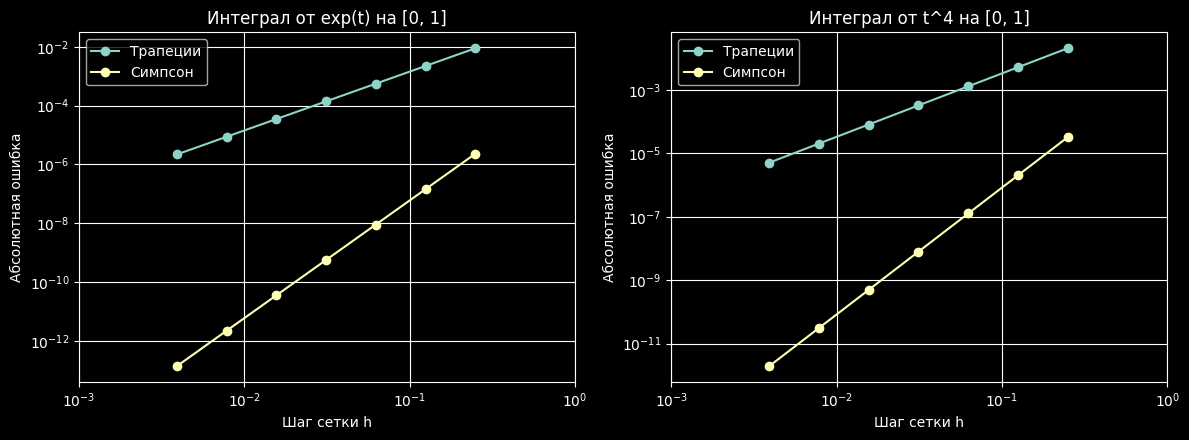

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
h_values = 1 / N_values

for ax, (title, func, exact) in zip(axes, examples):
    for name, method in methods:
        ax.loglog(h_values, simple_errors[title, name], "o-", label=name)
    ax.set_xlabel("Шаг сетки h")
    ax.set_ylabel("Абсолютная ошибка")
    ax.set_title("Интеграл от " + title + " на [0, 1]")
    ax.set_xlim(1e-3, 1)
    ax.set_xticks([1e-3, 1e-2, 1e-1, 1],
                  [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$"])
    ax.minorticks_off()
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

## Вычисление функций Бесселя.

Введём функцию, вычисляющую интеграл выбранным методом:

$$
    J_{m,N}(x)=\frac{1}{\pi}Q_N\bigl[\cos(mt-x\sin t)\bigr].
$$

Функция принимает как одно значение $x$, так и массив: одни и те же
узлы интегрирования используются для всех значений $x$.
Встроенные функции Бесселя и интегрирования не используются.

In [17]:
def find_bessel(m, x, N=64, method=find_simpson):
    x = np.asarray(x, dtype=float)

    def integrand(t):
        return np.cos(m * t - x * np.sin(t))

    return method(integrand, 0, np.pi, N) / np.pi


N_integral = 64
x_table = np.linspace(0, 2 * np.pi, 9)

for name, method in methods:
    print("\nМетод:", name, "; N =", N_integral)
    j0 = find_bessel(0, x_table, N_integral, method)
    j1 = find_bessel(1, x_table, N_integral, method)
    print(f"{'x':>10} {'J0(x)':>18} {'J1(x)':>18}")
    for x, v0, v1 in zip(x_table, j0, j1):
        print(f"{x:10.6f} {v0:18.12f} {v1:18.12f}")


Метод: Трапеции ; N = 64
         x              J0(x)              J1(x)
  0.000000     1.000000000000     0.000000000000
  0.785398     0.851631913705     0.363187838347
  1.570796     0.472001215768     0.566824088906
  2.356194     0.025495412254     0.529240338417
  3.141593    -0.304242177644     0.284615343180
  3.926991    -0.400947276632    -0.037853937894
  4.712389    -0.265857249958    -0.281657908751
  5.497787    -0.007599557755    -0.341559660394
  6.283185     0.220276908540    -0.212382530076

Метод: Симпсон ; N = 64
         x              J0(x)              J1(x)
  0.000000     1.000000000000     0.000000000000
  0.785398     0.851631913705     0.363187838347
  1.570796     0.472001215768     0.566824088906
  2.356194     0.025495412254     0.529240338417
  3.141593    -0.304242177644     0.284615343180
  3.926991    -0.400947276632    -0.037853937894
  4.712389    -0.265857249958    -0.281657908751
  5.497787    -0.007599557755    -0.341559660394
  6.283185     0.2

### Выбор сетки интегрирования:

Проверим изменение $J_0$ и $J_1$ при удвоении числа интервалов.
Для контроля используем $513$ точек на всём отрезке $[0,2\pi]$.

В этой задаче интегралы могут сходиться значительно быстрее общих оценок
$O(h^2)$ и $O(h^4)$. Действительно, функция
$\cos(mt-x\sin t)$ продолжается в гладкую $2\pi$-периодическую функцию,
чётную относительно $t=0$ и $t=\pi$. Её нечётные производные на концах
равны нулю, поэтому исчезают граничные члены формулы Эйлера—Маклорена.
Для формулы Симпсона это также следует из $S_N=(4T_{2N}-T_N)/3$.

Поэтому общий порядок методов проверяем на простых интегралах выше.
Сравнение соседних сеток здесь показывает устойчивость значений;
ниже дополнительно проверим их независимым степенным рядом.

In [18]:
x_control = np.linspace(0, 2 * np.pi, 513)
integral_changes = {}

for name, method in methods:
    print("\nМетод:", name)
    print(f"{'N -> 2N':>12} {'max |J(2N) - J(N)|, m=0,1':>30}")
    for n in [4, 8, 16, 32, 64]:
        change = max(
            np.max(np.abs(find_bessel(m, x_control, 2*n, method)
                          - find_bessel(m, x_control, n, method)))
            for m in [0, 1]
        )
        integral_changes[name, n] = change
        print(f"{n:4d} -> {2*n:<4d} {change:30.5e}")


Метод: Трапеции
     N -> 2N      max |J(2N) - J(N)|, m=0,1
   4 -> 8                       1.46591e-01
   8 -> 16                      1.12326e-05
  16 -> 32                      4.44089e-16
  32 -> 64                      6.66134e-16
  64 -> 128                     1.05471e-15

Метод: Симпсон
     N -> 2N      max |J(2N) - J(N)|, m=0,1
   4 -> 8                       4.88572e-02
   8 -> 16                      3.74421e-06
  16 -> 32                      5.55112e-16
  32 -> 64                      6.66134e-16
  64 -> 128                     1.22125e-15


## Производная с помощью конечной разности.

Для переменной $x$ используем отдельную равномерную сетку

$$
    x_i=i\Delta x, \qquad \Delta x=\frac{2\pi}{M}, \qquad i=0,\ldots,M.
$$

Пусть $y_i=J_{0,N}(x_i)$. Простая центральная разность имеет ошибку
$O(\Delta x^2)$. Чтобы достичь $10^{-10}$ без чрезмерно малого шага,
используем пятиузловую разность четвёртого порядка:

$$
    D_i=\frac{y_{i-2}-8y_{i-1}+8y_{i+1}-y_{i+2}}{12\Delta x},
    \qquad i=2,\ldots,M-2.
$$

У левого края берём формулы того же порядка:

$$
\begin{aligned}
    D_0&=\frac{-25y_0+48y_1-36y_2+16y_3-3y_4}{12\Delta x},\\
    D_1&=\frac{-3y_0-10y_1+18y_2-6y_3+y_4}{12\Delta x}.
\end{aligned}
$$

У правого края используем отражённые формулы с изменением знака.
Так производная вычисляется **во всех тех же узлах**, где вычислены
$J_0$ и $J_1$, включая $0$ и $2\pi$. Дополнительных значений за пределами
отрезка не требуется.

Из разложения Тейлора следует $D_i=J_0'(x_i)+O(\Delta x^4)$.
Численное дифференцирование также усиливает ошибки значений примерно
как $1/\Delta x$, поэтому бесконечно уменьшать шаг не следует.

In [19]:
def find_derivative(y, dx):
    y = np.asarray(y, dtype=float)
    if y.ndim != 1 or len(y) < 5:
        raise ValueError("Нужно не меньше пяти значений на равномерной сетке")

    derivative = np.empty_like(y)
    derivative[2:-2] = (y[:-4] - 8*y[1:-3] + 8*y[3:-1] - y[4:]) / (12*dx)
    derivative[0] = (-25*y[0] + 48*y[1] - 36*y[2] + 16*y[3] - 3*y[4]) / (12*dx)
    derivative[1] = (-3*y[0] - 10*y[1] + 18*y[2] - 6*y[3] + y[4]) / (12*dx)
    derivative[-2] = (3*y[-1] + 10*y[-2] - 18*y[-3] + 6*y[-4] - y[-5]) / (12*dx)
    derivative[-1] = (25*y[-1] - 48*y[-2] + 36*y[-3] - 16*y[-4] + 3*y[-5]) / (12*dx)
    return derivative

### Проверка разностной формулы на простом примере:

Для $y(x)=\sin x$ точная производная равна $\cos x$.
Проверим максимальную ошибку на всём отрезке $[0,2\pi]$, включая края.
На сгущающихся сетках ожидаем $p\to4$.

In [20]:
previous_error = None
derivative_orders = []
print(f"{'M':>6} {'max |D sin - cos|':>22} {'Порядок':>10}")
for m in [32, 64, 128, 256, 512]:
    x = np.linspace(0, 2*np.pi, m + 1)
    dx = 2*np.pi / m
    error = np.max(np.abs(find_derivative(np.sin(x), dx) - np.cos(x)))
    order = math.log2(previous_error / error) if previous_error is not None else None
    derivative_orders.append(order)
    order_text = "—" if order is None else f"{order:.4f}"
    print(f"{m:6d} {error:22.5e} {order_text:>10}")
    previous_error = error

     M      max |D sin - cos|    Порядок
    32            2.79779e-04          —
    64            1.83031e-05     3.9341
   128            1.15688e-06     3.9838
   256            7.25078e-08     3.9960
   512            4.53491e-09     3.9990


## Проверка равенства на сгущающихся сетках.

Зафиксируем $N=64$ для интегрирования и последовательно увеличим $M$.
В каждом узле вычислим невязку

$$
    r_i=D_i+J_{1,N}(x_i), \qquad
    r_{\max}=\max_{0\leq i\leq M}|r_i|.
$$

Это абсолютная невязка: относительная ошибка вблизи нулей функций
не подходит для проверки данного условия. Максимум берётся и по внутренним,
и по граничным узлам. Проверка относится к узлам сетки; конечный набор
значений сам по себе не является доказательством оценки между узлами.

In [21]:
eps = 1e-10
M_values = np.array([128, 256, 512, 1024, 2048])
residual_errors = {}

for name, method in methods:
    errors = []
    print("\nМетод:", name, "; N =", N_integral)
    print(f"{'M':>6} {'dx':>12} {'max |J0′ + J1|':>20} {'Порядок':>10}")
    for m in M_values:
        x = np.linspace(0, 2*np.pi, m + 1)
        dx = 2*np.pi / m
        j0 = find_bessel(0, x, N_integral, method)
        j1 = find_bessel(1, x, N_integral, method)
        residual = find_derivative(j0, dx) + j1
        error = np.max(np.abs(residual))
        order = math.log2(errors[-1] / error) if errors else None
        order_text = "—" if order is None else f"{order:.4f}"
        print(f"{m:6d} {dx:12.5e} {error:20.5e} {order_text:>10}")
        errors.append(error)
    residual_errors[name] = np.array(errors)


Метод: Трапеции ; N = 64
     M           dx       max |J0′ + J1|    Порядок
   128  4.90874e-02          1.61390e-07          —
   256  2.45437e-02          9.35149e-09     4.1092
   512  1.22718e-02          5.61112e-10     4.0588
  1024  6.13592e-03          3.44534e-11     4.0256
  2048  3.06796e-03          1.78044e-12     4.2743

Метод: Симпсон ; N = 64
     M           dx       max |J0′ + J1|    Порядок
   128  4.90874e-02          1.61390e-07          —
   256  2.45437e-02          9.35149e-09     4.1092
   512  1.22718e-02          5.61109e-10     4.0588
  1024  6.13592e-03          3.43945e-11     4.0280
  2048  3.06796e-03          2.08200e-12     4.0461


### Подробная проверка при $M=2048$:

Теперь на общей сетке из $2049$ точек выведем значения производной,
$J_1$ и невязки в нескольких узлах. Отдельно найдём максимумы
во внутренних и граничных узлах. Условие $r_{\max}\leq10^{-10}$
проверим программно для каждого метода.

In [22]:
M = 2048
x_grid = np.linspace(0, 2*np.pi, M + 1)
dx = 2*np.pi / M
results = {}

for name, method in methods:
    j0 = find_bessel(0, x_grid, N_integral, method)
    j1 = find_bessel(1, x_grid, N_integral, method)
    derivative = find_derivative(j0, dx)
    residual = derivative + j1
    max_index = np.argmax(np.abs(residual))
    max_error = np.abs(residual[max_index])
    results[name] = dict(j0=j0, j1=j1, derivative=derivative, residual=residual)

    print("\nМетод:", name)
    print(f"{'x':>10} {'J0′ (разность)':>20} {'J1':>18} {'J0′ + J1':>16}")
    for i in np.linspace(0, M, 9, dtype=int):
        print(f"{x_grid[i]:10.6f} {derivative[i]:20.12f} {j1[i]:18.12f} {residual[i]:16.5e}")
    print("Максимум во внутренних узлах:", np.max(np.abs(residual[2:-2])))
    print("Максимум в четырёх граничных узлах:", np.max(np.abs(residual[[0, 1, -2, -1]])))
    print(f"Общий максимум: {max_error:.5e}, x = {x_grid[max_index]:.8f}")
    print("Точность 1e-10 достигнута:", max_error <= eps)
    assert max_error <= eps, "Невязка превышает 1e-10"


Метод: Трапеции
         x       J0′ (разность)                 J1         J0′ + J1
  0.000000       0.000000000000     0.000000000000      2.77475e-13
  0.785398      -0.363187838346     0.363187838347      6.13898e-13
  1.570796      -0.566824088905     0.566824088906      9.68670e-13
  2.356194      -0.529240338416     0.529240338417      8.41660e-13
  3.141593      -0.284615343179     0.284615343180      2.64122e-13
  3.926991       0.037853937893    -0.037853937894     -4.50050e-13
  4.712389       0.281657908750    -0.281657908751     -8.07798e-13
  5.497787       0.341559660393    -0.341559660394     -7.66720e-13
  6.283185       0.212382530075    -0.212382530076     -1.78044e-12
Максимум во внутренних узлах: 1.059707877004712e-12
Максимум в четырёх граничных узлах: 1.780436909015748e-12
Общий максимум: 1.78044e-12, x = 6.28318531
Точность 1e-10 достигнута: True

Метод: Симпсон
         x       J0′ (разность)                 J1         J0′ + J1
  0.000000      -0.000000000000  

### График проверяемого равенства.

Перепишем равенство $J_0'(x)+J_1(x)=0$ в виде $J_0'(x)=-J_1(x)$ и построим обе его части на общей сетке $x\in[0,2\pi]$. Производная получена конечной разностью по значениям $J_0$, а $J_1$ — интегрированием.

Для каждого метода сплошная и пунктирная кривые совпадают в масштабе рисунка. Их малое различие показано ниже на графике невязки.

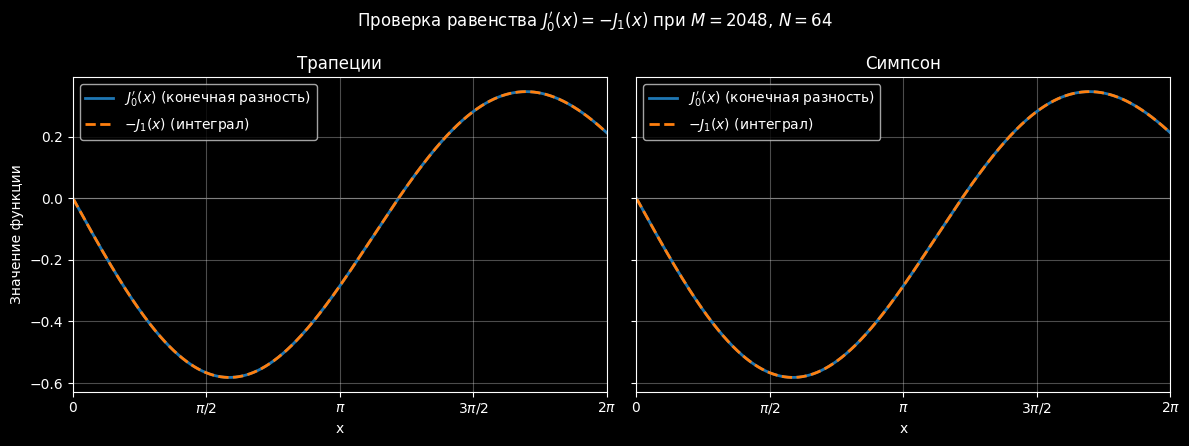

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (name, method) in zip(axes, methods):
    ax.plot(x_grid, results[name]["derivative"],
            color="tab:blue", linewidth=2, label=r"$J_0'(x)$ (конечная разность)")
    ax.plot(x_grid, -results[name]["j1"],
            color="tab:orange", linestyle="--", linewidth=2,
            label=r"$-J_1(x)$ (интеграл)")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlim(0, 2*np.pi)
    ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],
                  [r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
    ax.set_xlabel("x")
    ax.set_title(name)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Значение функции")
fig.suptitle(r"Проверка равенства $J_0'(x) = -J_1(x)$ при $M=2048$, $N=64$")
plt.tight_layout()
plt.show()

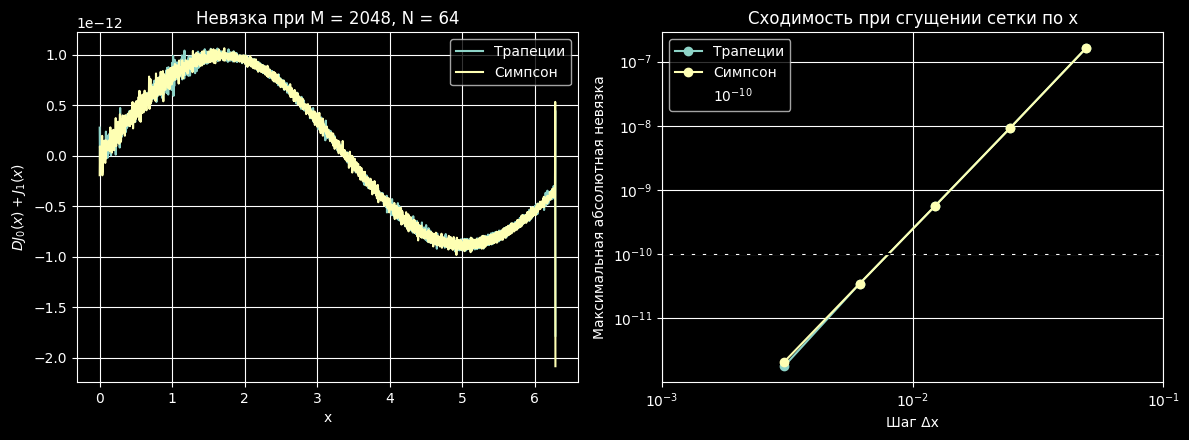

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, method in methods:
    axes[0].plot(x_grid, results[name]["residual"], label=name)
    axes[1].loglog(2*np.pi/M_values, residual_errors[name], "o-", label=name)

axes[0].set_xlabel("x")
axes[0].set_ylabel(r"$D J_0(x) + J_1(x)$")
axes[0].set_title("Невязка при M = 2048, N = 64")
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].set_xlabel("Шаг Δx")
axes[1].set_ylabel("Максимальная абсолютная невязка")
axes[1].set_title("Сходимость при сгущении сетки по x")
axes[1].axhline(eps, color="black", linestyle="--", label=r"$10^{-10}$")
axes[1].set_xlim(1e-3, 1e-1)
axes[1].set_xticks([1e-3, 1e-2, 1e-1],
                   [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$"])
axes[1].minorticks_off()
for ax in axes:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()